In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
CH='C:\\ex\\data\\21_cmapss_fd001_sample copy 2.csv'
df=pd.read_csv(CH)

sensors=['s_2','s_3','s_4','s_7','s_11']

e1=df[df['unit_nr']==1].reset_index(drop=True)

In [6]:
corr1=e1[sensors].corr()

In [7]:
corr1

,s_2,s_3,s_4,s_7,s_11
s_2,1.000000,0.949652,0.985629,-0.934855,0.813992
s_3,0.949652,1.000000,0.973544,-0.956611,0.837902
s_4,0.985629,0.973544,1.000000,-0.958716,0.827222
s_7,-0.934855,-0.956611,-0.958716,1.000000,-0.825653
s_11,0.813992,0.837902,0.827222,-0.825653,1.000000


In [8]:
s1=e1['s_3']

In [9]:
s1

0      1585.21
1      1585.55
2      1584.72
3      1585.94
4      1585.72
        ...   
187    1606.39
188    1608.47
189    1605.65
190    1606.83
191    1609.83
Name: s_3, Length: 192, dtype: float64

In [12]:
(s1>s1.mean() + 2*s1.std())|(s1<s1.mean() - 2*s1.std()).sum()

0      False
1      False
2      False
3      False
4      False
       ...  
187    False
188    False
189    False
190    False
191     True
Name: s_3, Length: 192, dtype: bool

In [14]:
mask=(s1>s1.mean() + 2*s1.std())|(s1<s1.mean() - 2*s1.std()).sum()

In [15]:
s1[mask]

179    1609.64
186    1610.44
191    1609.83
Name: s_3, dtype: float64

In [ ]:
# 21_03. 실습 1

In [16]:
CH='C:\\ex\\data\\21_cmapss_fd001_sample copy 2.csv'
df=pd.read_csv(CH)

e2=df[df['unit_nr']==2].reset_index(drop=True)
sensor=['s_2', 's_3', 's_4', 's_7', 's_11']

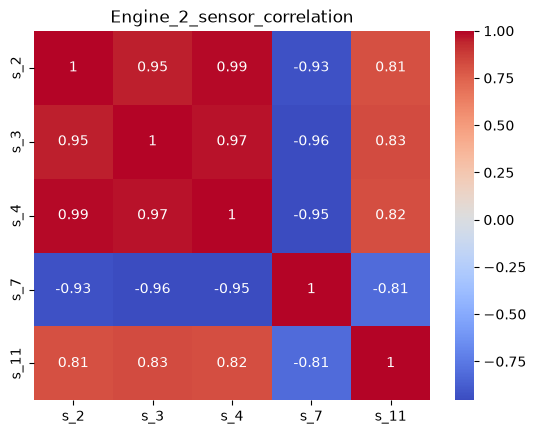

In [ ]:
sns.heatmap(e2[sensor].corr(), annot=True, cmap='coolwarm')

plt.title('Engine_2_sensor_correlation')
plt.show()

In [ ]:
# 21_03. 실습 2

In [32]:
corr=e2[sensor].corr()

In [40]:
corr.columns

Index(['s_2', 's_3', 's_4', 's_7', 's_11'], dtype='str')

In [ ]:
for i in sensor:
    for j in corr.columns:
        print(i)
        

s_2 [ 1.          0.95367797  0.98569067 -0.93240005  0.81044584]
s_2 [ 0.95367797  1.          0.97484812 -0.95668756  0.82737532]
s_2 [ 0.98569067  0.97484812  1.         -0.95342609  0.82279633]
s_2 [-0.93240005 -0.95668756 -0.95342609  1.         -0.81491889]
s_2 [ 0.81044584  0.82737532  0.82279633 -0.81491889  1.        ]
s_3 [ 1.          0.95367797  0.98569067 -0.93240005  0.81044584]
s_3 [ 0.95367797  1.          0.97484812 -0.95668756  0.82737532]
s_3 [ 0.98569067  0.97484812  1.         -0.95342609  0.82279633]
s_3 [-0.93240005 -0.95668756 -0.95342609  1.         -0.81491889]
s_3 [ 0.81044584  0.82737532  0.82279633 -0.81491889  1.        ]
s_4 [ 1.          0.95367797  0.98569067 -0.93240005  0.81044584]
s_4 [ 0.95367797  1.          0.97484812 -0.95668756  0.82737532]
s_4 [ 0.98569067  0.97484812  1.         -0.95342609  0.82279633]
s_4 [-0.93240005 -0.95668756 -0.95342609  1.         -0.81491889]
s_4 [ 0.81044584  0.82737532  0.82279633 -0.81491889  1.        ]
s_7 [ 1.  

In [53]:
corr = e2[sensor].corr()
pos_pairs = []
neg_pairs = []

for i in sensor:
    for j in corr.columns:
        # 자기 자신, 중복 쌍 (s_2-s_3 / s_3-s_2) 제거
        if sensor.index(i) >= sensor.index(j):
            continue

        c = corr.loc[i, j]

        if c >= 0.9:
            pos_pairs.append((i, j, round(c, 3)))
        elif c <= -0.9:
            neg_pairs.append((i, j, round(c, 3)))

print('# 양의 상관 쌍')
for i, j, c in pos_pairs:
    print(f'{i} - {j}: {c}')

print('-'*20)
print('# 음의 상관 쌍')
for i, j, c in neg_pairs:
    print(f'{i} - {j}: {c}')

# 양의 상관 쌍
s_2 - s_3: 0.954
s_2 - s_4: 0.986
s_3 - s_4: 0.975
--------------------
# 음의 상관 쌍
s_2 - s_7: -0.932
s_3 - s_7: -0.957
s_4 - s_7: -0.953


In [54]:
for i in range(len(sensors)):
    for j in range(i + 1, len(sensors)):
        c = corr.iloc[i, j]
        
        if abs(c) >= 0.9:
            print(sensors[i], '-', sensors[j], ':', round(c, 2))

s_2 - s_3 : 0.95
s_2 - s_4 : 0.99
s_2 - s_7 : -0.93
s_3 - s_4 : 0.97
s_3 - s_7 : -0.96
s_4 - s_7 : -0.95


In [56]:
import numpy as np
help(np.triu)

Help on method descriptor triu in module numpy:

triu(m, k=0)
    Upper triangle of an array.

    Return a copy of an array with the elements below the `k`-th diagonal
    zeroed. For arrays with ``ndim`` exceeding 2, `triu` will apply to the
    final two axes.

    Please refer to the documentation for `tril` for further details.

    See Also
    --------
    tril : lower triangle of an array

    Examples
    --------
    >>> import numpy as np
    >>> np.triu([[1,2,3],[4,5,6],[7,8,9],[10,11,12]], -1)
    array([[ 1,  2,  3],
           [ 4,  5,  6],
           [ 0,  8,  9],
           [ 0,  0, 12]])

    >>> np.triu(np.arange(3*4*5).reshape(3, 4, 5))
    array([[[ 0,  1,  2,  3,  4],
            [ 0,  6,  7,  8,  9],
            [ 0,  0, 12, 13, 14],
            [ 0,  0,  0, 18, 19]],
           [[20, 21, 22, 23, 24],
            [ 0, 26, 27, 28, 29],
            [ 0,  0, 32, 33, 34],
            [ 0,  0,  0, 38, 39]],
           [[40, 41, 42, 43, 44],
            [ 0, 46, 47, 48

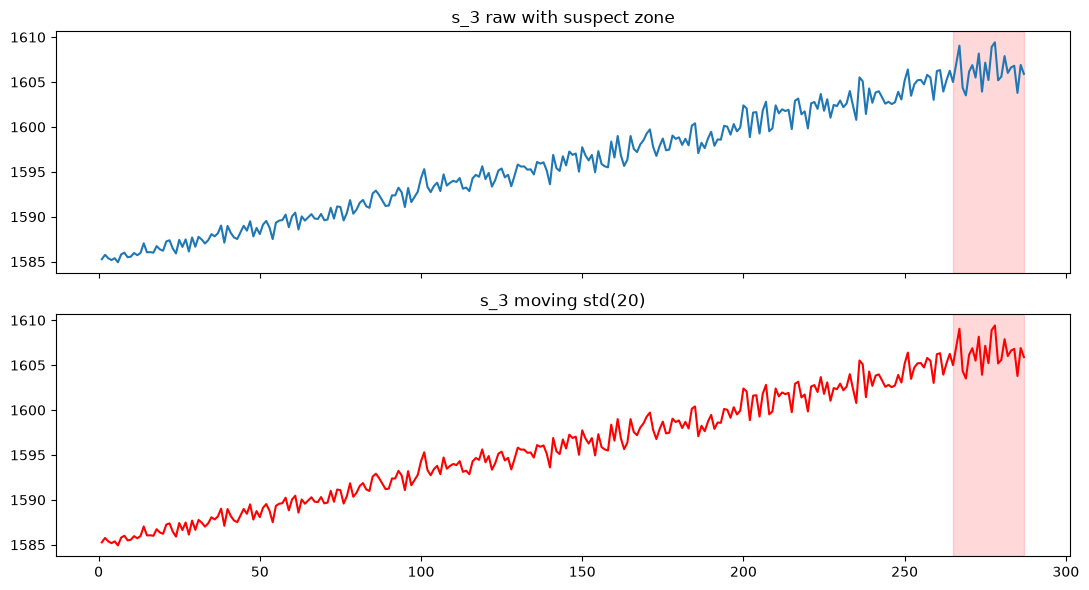

In [ ]:
std20=e2['s_3']

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(11,6), sharex=True)

ax1.plot(e2['time_cycles'], e2['s_3']); ax1.axvspan(265, 287, color='red', alpha=0.15)
ax1.set_title('s_3 raw with suspect zone')

ax2.plot(e2['time_cycles'], std20, color='red'); ax2.axvspan(265, 287, color='red', alpha=0.15)
ax2.set_title('s_3 moving std(20)')

plt.tight_layout(); plt.show()
